# Reciprocity

Introducing reciprocity of pairwise relations and plotting bi-dimensional distributions (of in- and outgoing strength).

## 0. Set Up

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import normalize


from network_pluralism.access.resolved import to_level
from network_pluralism.access.projected import to_projection
from network_pluralism.access.utils.df import sparse_matrix_to_edge_list
from network_pluralism.setup.params import (
    DECISION_LEVEL_COLOR,
    DEFAULT_COLOR,
)

In [2]:

def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        #"text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}\usepackage{amsfonts}\usepackage{lmodern}",
        "font.size": 12,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [3]:
EXPORT_PATH = Path("../../figures_and_results/reciprocity")
EXPORT_PATH.mkdir(parents=True, exist_ok=True)

## 1. Computation

In [4]:
level = 2 # at the decision level
minimum_total_coreference = 10
norm_function = "l1"

In [5]:
procedural_norms = [
    "vwgo_154",
    "zpo_563",
    "gg_3",
    "fgo_126",
    "zpo_97",
    "vwgo_137",
    "zpo_562",
    "fgo_135",
    "gkg_2004_52" ,
    "gg_2",
    "gg_103" ,
    "sgg_193",
    "sgg_170",
    "stpo_349",
    "vwgo_132",
]
procedural_norms = procedural_norms[:10]
procedural_norms

['vwgo_154',
 'zpo_563',
 'gg_3',
 'fgo_126',
 'zpo_97',
 'vwgo_137',
 'zpo_562',
 'fgo_135',
 'gkg_2004_52',
 'gg_2']

In [6]:
m_dec, r, c = to_level(level, 1)
m_projection_dec = to_projection(m_dec)
m_projection_dec.setdiag(0)
m_projection_dec.eliminate_zeros()
m_projection_dec

Out Matrix of shape (74214, 93645)


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2516616 stored elements and shape (93645, 93645)>

In [7]:
m_projection_dec_scaled_row = normalize(m_projection_dec, norm=norm_function)
#m_projection_dec_scaled_row = m_projection_dec / m_projection_dec.max(axis=1).toarray()
scaled_row_df = sparse_matrix_to_edge_list(m_projection_dec_scaled_row,c,c)

In [8]:
m_projection_dec_scaled_col = normalize(m_projection_dec, norm=norm_function, axis=0)
# m_projection_dec_scaled_col = m_projection_dec / m_projection_dec.max(axis=0).toarray()
scaled_col_df = sparse_matrix_to_edge_list(m_projection_dec_scaled_col, c, c)

In [9]:
merged_scaled_df = scaled_row_df.merge(scaled_col_df,on=['r_sem', 'c_sem'])
merged_scaled_df.head()

,r_num_x,c_num_x,num_x,r_sem,c_sem,r_num_y,c_num_y,num_y
0,83,36559,0.142857,_appro_2002_2,gg_12,83,36559,0.000057
1,83,36622,0.142857,_appro_2002_2,gg_3,83,36622,0.000027
2,83,36647,0.142857,_appro_2002_2,gg_5,83,36647,0.000183
3,83,86305,0.142857,_appro_2002_2,vwgo_137,83,86305,0.000046
4,83,86325,0.142857,_appro_2002_2,vwgo_154,83,86325,0.000025


In [10]:
freq_table = pd.DataFrame(m_projection_dec.sum(axis=0).A1, index=c.keys(),columns=['num_of_coocs'])
freq_table

,num_of_coocs
1-dm-goldm_nzg_1,0.0
1-dm-goldm_nzg_10,0.0
1-dm-goldm_nzg_11,0.0
1-dm-goldm_nzg_12,0.0
1-dm-goldm_nzg_13,0.0
...,...
zwvwv_5,72.0
zwvwv_6,34.0
zwvwv_7,13.0
zwvwv_8,0.0


In [11]:
rec_df = merged_scaled_df.groupby("r_sem").mean(["num_x", "num_y"])[["num_x", "num_y"]]
rec_df['diff'] = rec_df['num_x'] - rec_df['num_y']
rec_df = rec_df.join(pd.DataFrame(m_projection_dec.sum(axis=0).A1, index=c.keys(),columns=['num_of_coocs']))
rec_df = rec_df[rec_df['num_of_coocs'] > minimum_total_coreference]
rec_df.head()

,num_x,num_y,diff,num_of_coocs
r_sem,,,,
_appro_2002_2,0.142857,0.000104,0.142754,14.0
_appro_2002_4,0.052632,0.000734,0.051898,19.0
_arbvtrg_1,0.034483,0.006332,0.028151,31.0
_kokennzg_1,0.076923,0.012602,0.064321,13.0
_kokennzg_2,0.076923,0.012602,0.064321,13.0


In [12]:
highlight_df = rec_df[rec_df.index.isin(procedural_norms)]

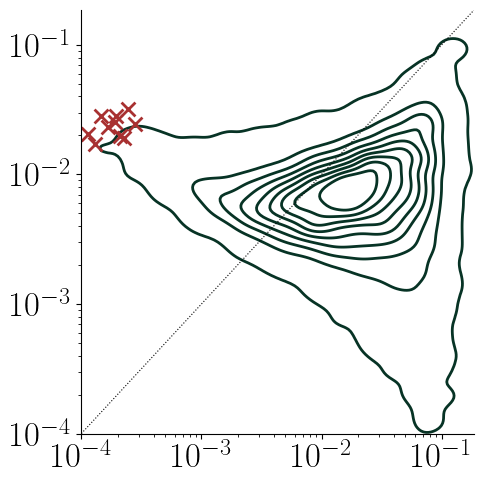

In [13]:
plt.figure(figsize=(5, 5))

sns.kdeplot(
    data=rec_df,  # rec_df[~rec_df.index.isin(procedural_norms)],
    x="num_x",
    y="num_y",
    thresh=0.005,
    levels=10,
    fill=False,
    linewidths=2,
    ax=plt.gca(),
    zorder=1,
    log_scale=True,
    color=DEFAULT_COLOR,
)

fix = 0

# Below is to dynamically set lims
ax = plt.gca()
xs, ys = [], []
for coll in getattr(ax, "collections", []):
    try:
        paths = coll.get_paths()
    except Exception:
        continue
    for p in paths:
        verts = p.vertices
        if verts.size:
            xs.append(np.nanmax(verts[:, 0]))
            ys.append(np.nanmax(verts[:, 1]))

if xs and ys:
    upper_lim = max(max(xs), max(ys)) * 1.05  # add small margin
else:
    upper_lim = max(rec_df["num_x"].max(), rec_df["num_y"].max()) * 1.05

min_lin = 0.0001
plt.xlim(min_lin, upper_lim)
plt.ylim(min_lin, upper_lim)

sns.scatterplot(
    data=highlight_df,
    x="num_x",
    y="num_y",
    color=DECISION_LEVEL_COLOR,
    marker="x",
    linewidth=2,
    s=100,
)

plt.axline((1, 1), (upper_lim, upper_lim), color="black", linewidth=0.8, linestyle=":")

plt.xlabel("")
plt.ylabel("")
plt.tick_params("both", labelsize=25)
plt.tight_layout()

plt.savefig(EXPORT_PATH / "reciprocity.pdf", dpi=600)
